<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/susy_qm/susyqm_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Quantum Mechanics* — `susyqm_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SUSYQM Ch 3 Figures — Colab Notebook
**Supersymmetric Quantum Mechanics · Chapter 3: Supersymmetry and Geometry**

| Figure | Section | Content |
|--------|---------|---------|
| fig01  | §3.1   | Sigma model: particle on manifold M, differential forms as states |
| fig02  | §3.1.2 | de Rham cohomology: closed/exact forms, Hodge decomposition |
| fig03  | §3.1.3 | Witten index = Euler characteristic χ(M) for manifolds S², T², S¹×S¹ |
| fig04  | §3.2   | Morse theory: critical points, index, gradient flow lines |
| fig05  | §3.3   | Atiyah-Singer index theorem: Dirac operator, spin complex, heat kernel |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Arc, Circle
import os

BG    = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
PURP  = '#c792ea'; BLUE = '#7ec8e3'; YELL = '#f9c74f'
GREEN = '#90ee90'; RED  = '#e07070'; ORAN = '#e8a838'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': PURP, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete — SUSYQM Ch 3 figures.')


Setup complete — SUSYQM Ch 3 figures.


<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6988/2077273151.py:42: SyntaxWarning: invalid escape sequence '\l'
  ax.set_title('SUSY $\leftrightarrow$ Differential Geometry', color=PURP)


  saved -> figures/ch03/fig01_sigma_model.png


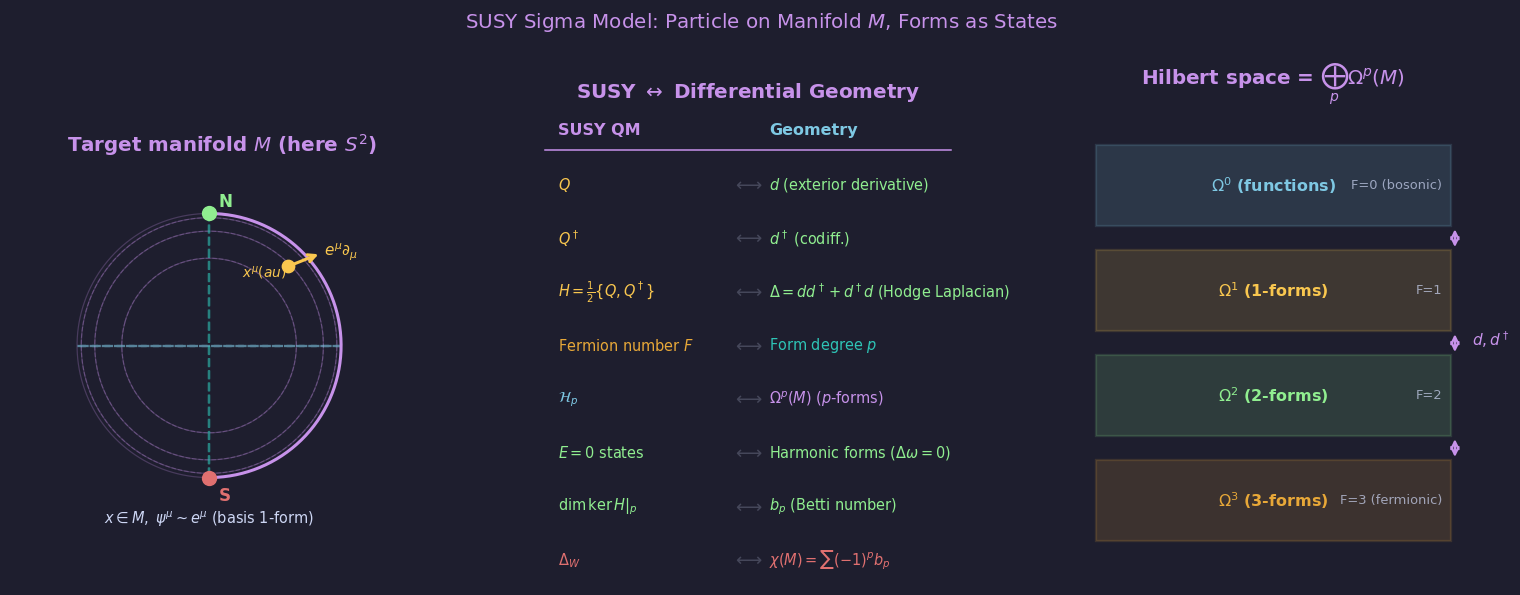

In [2]:
# ── Figure 1: Sigma model — forms as quantum states ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fig.suptitle(r'SUSY Sigma Model: Particle on Manifold $M$, Forms as States',
             color=PURP, fontsize=13)

# Left: S^2 surface with tangent vectors (forms)
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'Target manifold $M$ (here $S^2$)', color=PURP)
theta = np.linspace(0, np.pi, 80)
phi_arr = np.linspace(0, 2*np.pi, 120)
th, ph = np.meshgrid(theta, phi_arr)
xs = np.sin(th)*np.cos(ph)
ys = np.sin(th)*np.sin(ph)
zs = np.cos(th)
ax.contour(xs, zs, ys, levels=8, colors=[PURP], alpha=0.25, linewidths=0.8)
circle_eq = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(circle_eq), np.zeros(200), color=BLUE, lw=1.5, alpha=0.6, ls='--')
ax.plot(np.zeros(200), np.cos(circle_eq), color=TEAL, lw=1.5, alpha=0.6, ls='--')
theta_p = np.linspace(0, np.pi, 200)
ax.plot(np.sin(theta_p), np.cos(theta_p), color=PURP, lw=2)
# Mark north/south pole
ax.plot(0, 1, 'o', color=GREEN, ms=9, zorder=5)
ax.plot(0, -1, 'o', color=RED,   ms=9, zorder=5)
ax.text(0.07, 1.05, 'N', color=GREEN, fontsize=11, fontweight='bold')
ax.text(0.07,-1.18, 'S', color=RED,   fontsize=11, fontweight='bold')
# A point with tangent vector
px, py = 0.6, 0.6
ax.plot(px, py, 'o', color=YELL, ms=8, zorder=6)
ax.annotate('', xy=(px+0.25, py+0.1), xytext=(px, py),
            arrowprops=dict(arrowstyle='->', color=YELL, lw=2))
ax.text(px+0.27, py+0.08, r'$e^\mu\partial_\mu$', color=YELL, fontsize=10)
ax.text(px-0.35, py-0.08, r'$x^\mu(\tau)$', color=YELL, fontsize=9)
ax.set_xlim(-1.5,1.7); ax.set_ylim(-1.4,1.4)
ax.set_aspect('equal'); ax.axis('off')
ax.text(0, -1.35, r'$x\in M,\;\psi^\mu\sim e^\mu$ (basis 1-form)',
        ha='center', fontsize=9.5, color=FG)

# Middle: SUSY ↔ de Rham dictionary
ax = axes[1]
ax.set_facecolor(BG)
ax.set_title('SUSY $\leftrightarrow$ Differential Geometry', color=PURP)
ax.axis('off')

rows = [
    ('SUSY QM',                 'Geometry',                PURP, BLUE),
    (r'$Q$',                    r'$d$ (exterior derivative)', YELL, GREEN),
    (r'$Q^\dagger$',            r'$d^\dagger$ (codiff.)',   YELL, GREEN),
    (r'$H = \frac{1}{2}\{Q,Q^\dagger\}$', r'$\Delta = dd^\dagger+d^\dagger d$ (Hodge Laplacian)',
     YELL, GREEN),
    (r'Fermion number $F$',     r'Form degree $p$',        ORAN, TEAL),
    (r'$\mathcal{H}_p$',        r'$\Omega^p(M)$ ($p$-forms)', BLUE, PURP),
    (r'$E=0$ states',           r'Harmonic forms ($\Delta\omega=0$)', GREEN, GREEN),
    (r'$\dim \ker H|_p$',       r'$b_p$ (Betti number)',   GREEN, GREEN),
    (r'$\Delta_W$',             r'$\chi(M) = \sum(-1)^p b_p$', RED, RED),
]
ys = np.linspace(0.95, 0.05, len(rows))
for (lhs, rhs, cl, cr), y in zip(rows, ys):
    if lhs == 'SUSY QM':
        ax.text(0.05, y, lhs, fontsize=10.5, color=PURP, fontweight='bold',
                va='center', transform=ax.transAxes)
        ax.text(0.55, y, rhs, fontsize=10.5, color=BLUE, fontweight='bold',
                va='center', transform=ax.transAxes)
        ax.axhline(y-0.04, xmin=0.02, xmax=0.98, color=PURP, lw=1) #, transform=ax.transAxes)
    else:
        ax.text(0.05, y, lhs, fontsize=9.5, color=cl, va='center',
                transform=ax.transAxes)
        ax.text(0.5, y, r'$\longleftrightarrow$', fontsize=12, color=EDGE,
                va='center', ha='center', transform=ax.transAxes)
        ax.text(0.55, y, rhs, fontsize=9.5, color=cr, va='center',
                transform=ax.transAxes)

# Right: Hilbert space decomposition by form degree
ax = axes[2]
ax.set_facecolor(BG)
ax.set_title(r'Hilbert space = $\bigoplus_p \Omega^p(M)$', color=PURP)
ax.axis('off')
n_dim = 3
cols_f = [BLUE, YELL, GREEN, ORAN]
labels = [r'$\Omega^0$ (functions)', r'$\Omega^1$ (1-forms)',
          r'$\Omega^2$ (2-forms)', r'$\Omega^3$ (3-forms)']
fermion_n = ['F=0 (bosonic)', 'F=1', 'F=2', 'F=3 (fermionic)']
xs_box = [0.08]*4
widths  = [0.84]*4
ys_box  = [0.75, 0.53, 0.31, 0.09]
for i, (xb, yb, col, lab, fn) in enumerate(zip(xs_box, ys_box, cols_f, labels, fermion_n)):
    rect = plt.Rectangle((xb, yb), widths[i], 0.17,
                          facecolor=col, alpha=0.15, edgecolor=col,
                          transform=ax.transAxes, linewidth=1.5)
    ax.add_patch(rect)
    ax.text(xb+0.42, yb+0.085, lab, ha='center', va='center',
            fontsize=10.5, color=col, transform=ax.transAxes, fontweight='bold')
    ax.text(xb+widths[i]-0.02, yb+0.085, fn, ha='right', va='center',
            fontsize=8.5, color=FG, alpha=0.7, transform=ax.transAxes)

# Q arrows between levels
for y_from, y_to in zip(ys_box[:-1], ys_box[1:]):
    ax.annotate('', xy=(0.93, y_to+0.17), xytext=(0.93, y_from),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='<->', color=PURP, lw=1.5))
ax.text(0.97, 0.50, r'$d, d^\dagger$', ha='left', fontsize=10, color=PURP,
        transform=ax.transAxes)

plt.tight_layout()
save('fig01_sigma_model.png', fig)


  saved -> figures/ch03/fig02_de_rham.png


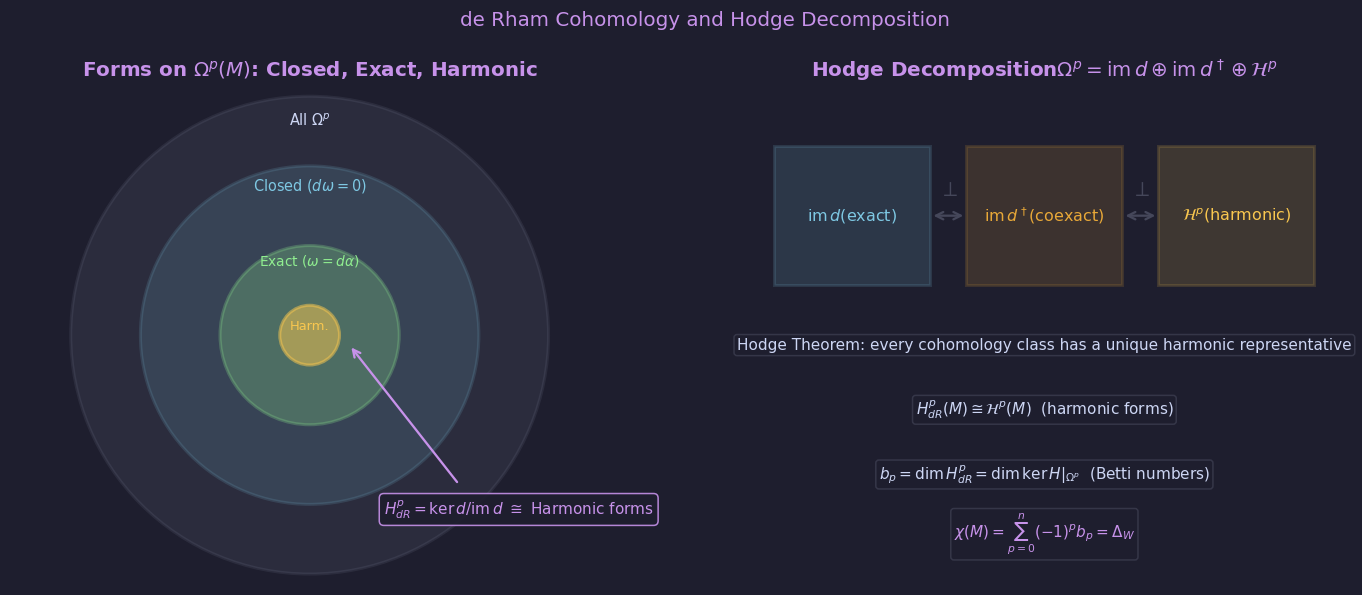

In [3]:
# ── Figure 2: de Rham cohomology and Hodge decomposition ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('de Rham Cohomology and Hodge Decomposition', color=PURP, fontsize=13)

# Left: concentric set diagram — exact ⊂ closed ⊂ all forms
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'Forms on $\Omega^p(M)$: Closed, Exact, Harmonic', color=PURP)
ax.set_xlim(-3, 3); ax.set_ylim(-2.5, 2.5); ax.set_aspect('equal'); ax.axis('off')

circles = [
    (0, 0, 2.4, FG,   0.08, r'All $p$-forms $\Omega^p$'),
    (0, 0, 1.7, BLUE, 0.15, r'Closed: $d\omega=0$'),
    (0, 0, 0.9, GREEN,0.25, r'Exact: $\omega=d\alpha$'),
    (0, 0, 0.3, YELL, 0.5,  r'Harmonic $\Delta\omega=0$'),
]
for cx, cy, r, col, alpha, label in circles:
    circ = plt.Circle((cx, cy), r, fill=True, facecolor=col, alpha=alpha,
                       edgecolor=col, linewidth=2)
    ax.add_patch(circ)

ax.text(0,  2.1, r'All $\Omega^p$',   ha='center', fontsize=9.5, color=FG)
ax.text(0,  1.45, r'Closed ($d\omega=0$)', ha='center', fontsize=9.5, color=BLUE)
ax.text(0,  0.7,  r'Exact ($\omega=d\alpha$)', ha='center', fontsize=9, color=GREEN)
ax.text(0,  0.05, r'Harm.',           ha='center', fontsize=8.5, color=YELL)

ax.text(2.1, -1.8,
        r'$H^p_{dR} = \ker d / \mathrm{im}\,d$' + ' ' + r'$\cong$ Harmonic forms',
        ha='center', fontsize=10, color=PURP,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=PURP, alpha=0.9))
# Arrow pointing to harmonic
ax.annotate('', xy=(0.4, -0.1), xytext=(1.5, -1.5),
            arrowprops=dict(arrowstyle='->', color=PURP, lw=1.5))

# Right: Hodge decomposition illustrated
ax = axes[1]
ax.set_facecolor(BG)
ax.set_title('Hodge Decomposition' +
             r'$\Omega^p = \mathrm{im}\,d \oplus \mathrm{im}\,d^\dagger \oplus \mathcal{H}^p$',
             color=PURP)
ax.axis('off')

# Three boxes
boxes = [
    (0.05, 0.60, 0.26, r'$\mathrm{im}\,d$' + '(exact)', BLUE),
    (0.37, 0.60, 0.26, r'$\mathrm{im}\,d^\dagger$' + '(coexact)', ORAN),
    (0.69, 0.60, 0.26, r'$\mathcal{H}^p$' + '(harmonic)', YELL),
]
for xb, yb, w, label, col in boxes:
    rect = plt.Rectangle((xb, yb), w, 0.28,
                          facecolor=col, alpha=0.15, edgecolor=col, linewidth=2,
                          transform=ax.transAxes)
    ax.add_patch(rect)
    ax.text(xb+w/2, yb+0.14, label, ha='center', va='center',
            fontsize=10.5, color=col, transform=ax.transAxes)

# Orthogonality arrows
for x1, x2, y_arr in [(0.31, 0.37, 0.74), (0.63, 0.69, 0.74)]:
    ax.annotate('', xy=(x2, y_arr), xytext=(x1, y_arr),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='<->', color=EDGE, lw=1.5))
ax.text(0.34, 0.78, r'$\perp$', ha='center', fontsize=14, color=EDGE,
        transform=ax.transAxes)
ax.text(0.66, 0.78, r'$\perp$', ha='center', fontsize=14, color=EDGE,
        transform=ax.transAxes)

key_results = [
    (0.5, 0.48, r'Hodge Theorem: every cohomology class has a unique harmonic representative'),
    (0.5, 0.35, r'$H^p_{dR}(M) \cong \mathcal{H}^p(M)$  (harmonic forms)'),
    (0.5, 0.22, r'$b_p = \dim H^p_{dR} = \dim\ker H|_{\Omega^p}$  (Betti numbers)'),
    (0.5, 0.10, r'$\chi(M) = \sum_{p=0}^n (-1)^p b_p = \Delta_W$'),
]
for x_, y_, txt in key_results:
    col = PURP if 'chi' in txt or 'Delta' in txt else FG
    ax.text(x_, y_, txt, ha='center', va='center', fontsize=10, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=EDGE, alpha=0.6))

plt.tight_layout()
save('fig02_de_rham.png', fig)


  saved -> figures/ch03/fig03_euler_characteristic.png


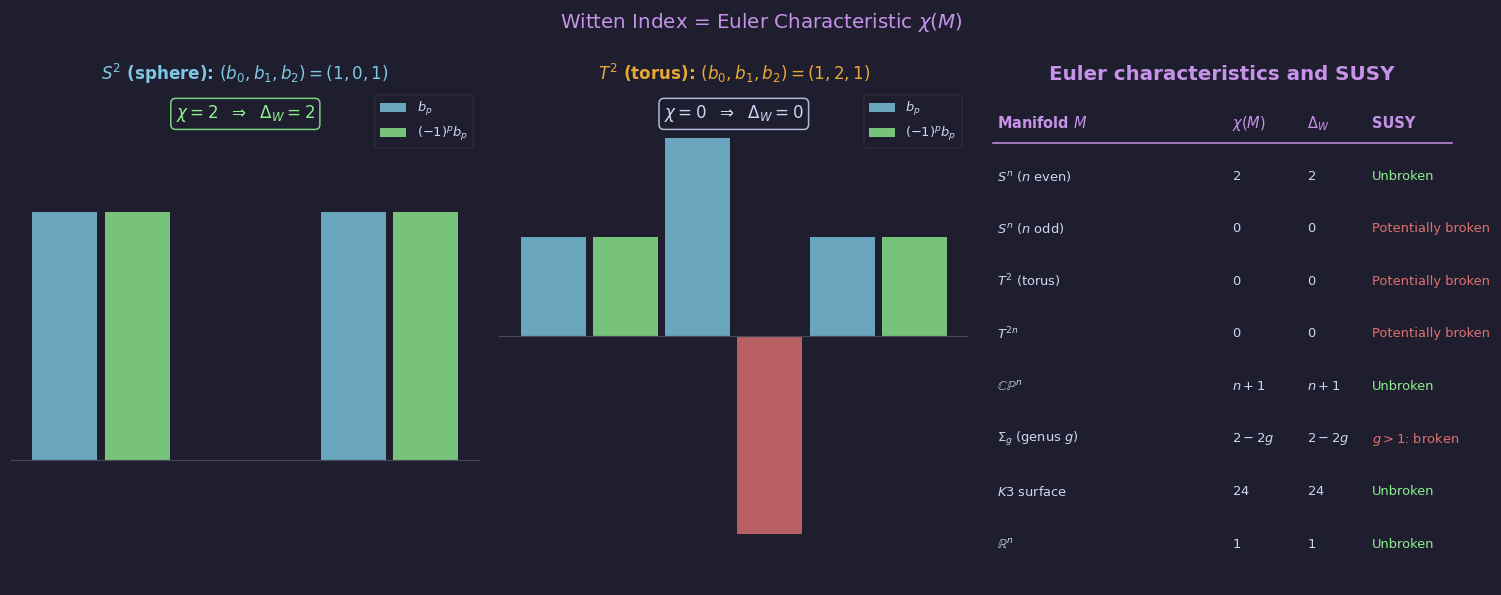

In [4]:
# ── Figure 3: χ(M) for S², T², RP², and Witten index table ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fig.suptitle(r'Witten Index = Euler Characteristic $\chi(M)$',
             color=PURP, fontsize=13)

def draw_circle_with_handles(ax, title, betti, chi_val, col):
    ax.set_facecolor(BG)
    ax.set_title(title, color=col, fontsize=11)
    ax.axis('off')
    # Betti numbers as bar chart
    ps = list(range(len(betti)))
    colors_b = [BLUE if b%2==0 else YELL for b in ps]
    ax.bar([p-0.25 for p in ps], betti, 0.45, color=BLUE, alpha=0.8,
           label=r'$b_p$')
    # (-1)^p * b_p
    signed = [(-1)**p * b for p, b in enumerate(betti)]
    ax.bar([p+0.25 for p in ps], signed, 0.45,
           color=[GREEN if s>=0 else RED for s in signed], alpha=0.8,
           label=r'$(-1)^p b_p$')
    ax.axhline(0, color=EDGE, lw=0.8)
    ax.set_xticks(ps)
    ax.set_xticklabels([f'$b_{p}$' for p in ps])
    ax.set_ylabel('value')
    ax.legend(fontsize=8.5, loc='upper right')
    ax.set_ylim(min(signed)-0.5, max(betti)+0.5)
    chi_col = GREEN if chi_val > 0 else (RED if chi_val < 0 else FG)
    ax.text(0.5, 0.94,
            r'$\chi = ' + str(chi_val) + r'$  $\Rightarrow$  ' +
            (r'$\Delta_W = ' + str(chi_val) + '$'),
            ha='center', transform=ax.transAxes, fontsize=11, color=chi_col,
            bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=chi_col, alpha=0.85))

# S^2: b_0=1, b_1=0, b_2=1; chi=2
draw_circle_with_handles(axes[0],
    r'$S^2$ (sphere): $(b_0,b_1,b_2)=(1,0,1)$',
    [1, 0, 1], 2, BLUE)

# T^2: b_0=1, b_1=2, b_2=1; chi=0
draw_circle_with_handles(axes[1],
    r'$T^2$ (torus): $(b_0,b_1,b_2)=(1,2,1)$',
    [1, 2, 1], 0, ORAN)

# Summary table panel
ax = axes[2]
ax.set_facecolor(BG)
ax.set_title(r'Euler characteristics and SUSY', color=PURP)
ax.axis('off')

headers = ['Manifold $M$', r'$\chi(M)$', r'$\Delta_W$', 'SUSY']
rows_data = [
    [r'$S^n$ ($n$ even)', r'$2$',  r'$2$',  'Unbroken'],
    [r'$S^n$ ($n$ odd)',  r'$0$',  r'$0$',  'Potentially broken'],
    [r'$T^2$ (torus)',    r'$0$',  r'$0$',  'Potentially broken'],
    [r'$T^{2n}$',         r'$0$',  r'$0$',  'Potentially broken'],
    [r'$\mathbb{CP}^n$',  r'$n+1$',r'$n+1$','Unbroken'],
    [r'$\Sigma_g$ (genus $g$)', r'$2-2g$', r'$2-2g$', r'$g>1$: broken'],
    [r'$K3$ surface',     r'$24$', r'$24$', 'Unbroken'],
    [r'$\mathbb{R}^n$',   r'$1$',  r'$1$',  'Unbroken'],
]
col_xs = [0.02, 0.52, 0.68, 0.82]
row_ys = np.linspace(0.93, 0.08, len(rows_data)+1)

for j, h in enumerate(headers):
    ax.text(col_xs[j], row_ys[0], h, ha='left', va='center', fontsize=9.5,
            color=PURP, fontweight='bold', transform=ax.transAxes)
ax.axhline(row_ys[0]-0.04, xmin=0.01, xmax=0.99, color=PURP, lw=1) #, transform=ax.transAxes)

for i, row in enumerate(rows_data):
    y = row_ys[i+1]
    for j, val in enumerate(row):
        col = GREEN if 'Unbroken' in val else (RED if 'broken' in val or 'Potentially' in val else FG)
        ax.text(col_xs[j], y, val, ha='left', va='center', fontsize=8.5,
                color=col, transform=ax.transAxes)

plt.tight_layout()
save('fig03_euler_characteristic.png', fig)


  saved -> figures/ch03/fig04_morse_theory.png


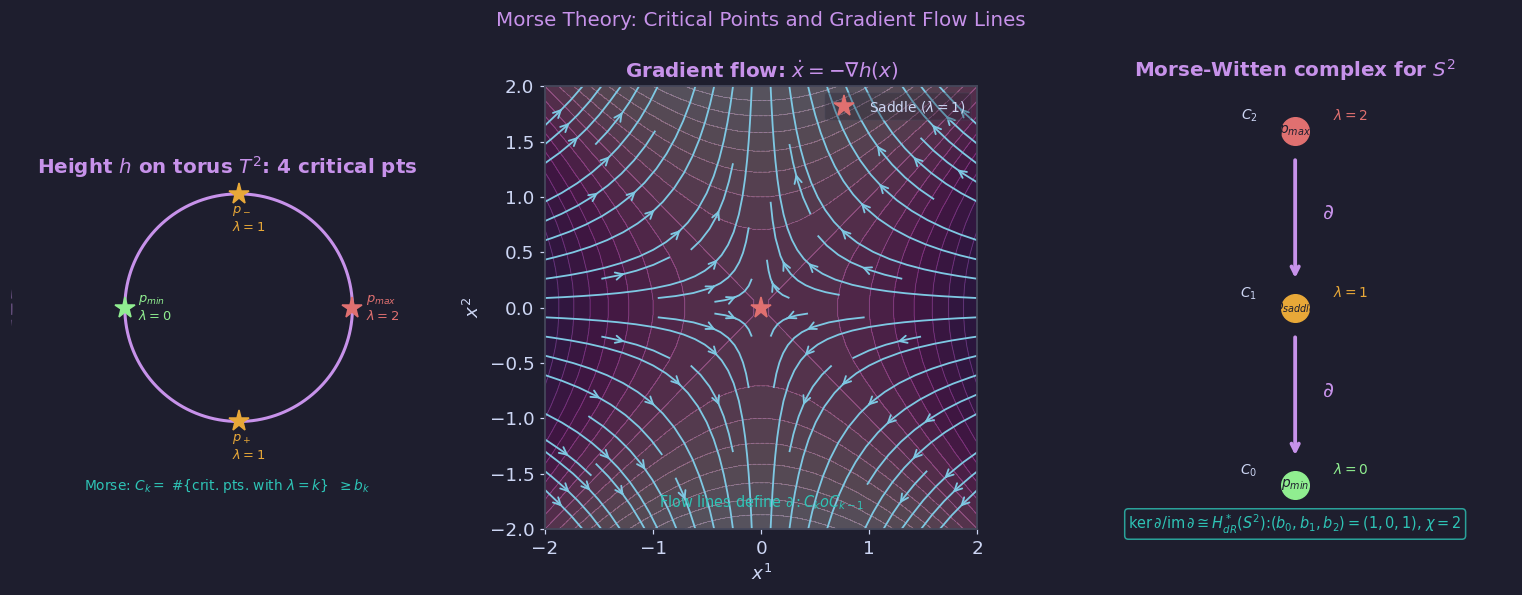

In [5]:
# ── Figure 4: Morse theory — critical points, gradient flows, complex ───────
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fig.suptitle('Morse Theory: Critical Points and Gradient Flow Lines',
             color=PURP, fontsize=13)

# Left: height function on T^2 (torus) with critical points
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'Height $h$ on torus $T^2$: 4 critical pts', color=PURP)

# Schematic torus cross-section
theta_t = np.linspace(0, 2*np.pi, 300)
R, r_small = 1.5, 1.0
xs_t = (R + r_small*np.cos(theta_t))
ys_t = r_small*np.sin(theta_t)
ax.plot(xs_t, ys_t, color=PURP, lw=2)
ax.plot(-(xs_t), ys_t, color=PURP, lw=2, ls='--', alpha=0.4)

# Mark critical points on torus
crit_pts = [
    (R+r_small,  0,    'max',   r'$p_{max}$'+'\n'+r'$\lambda=2$',  RED,   '$b_2=1$'),
    (R,      r_small,  'saddle',r'$p_-$'+'\n'+r'$\lambda=1$',      ORAN,  '$b_1=...$'),
    (R,     -r_small,  'saddle',r'$p_+$'+'\n'+r'$\lambda=1$',      ORAN,  ''),
    (R-r_small,  0,    'min',   r'$p_{min}$'+'\n'+r'$\lambda=0$',  GREEN, '$b_0=1$'),
]
for i, (cx, cy, kind, lbl, col, betti) in enumerate(crit_pts):
    ax.plot(cx, cy, '*', color=col, ms=14, zorder=6)
    if i in [0, 3]:
        ax.text(cx+0.12, cy, lbl, fontsize=8.5, color=col, va='center')
    else:
        ax.text(cx -0.06, cy -0.22, lbl, fontsize=8.5, color=col, va='center')

ax.set_xlim(-0.5, 3.3); ax.set_ylim(-1.1, 1.1)
ax.set_aspect('equal'); ax.axis('off')
ax.text(1.4, -1.6,
        r'Morse: $C_k = $ #{crit. pts. with $\lambda=k$}' + r'  $\geq b_k$',
        ha='center', fontsize=9, color=TEAL)

# Middle: gradient flow lines (Morse complex)
ax = axes[1]
ax.set_facecolor(BG)
ax.set_title(r'Gradient flow: $\dot{x} = -\nabla h(x)$', color=PURP)

# 2D Morse function: h(x,y) = x^2 - y^2 (saddle) near origin
x_m = np.linspace(-2, 2, 30)
y_m = np.linspace(-2, 2, 30)
X_m, Y_m = np.meshgrid(x_m, y_m)
H_m = X_m**2 - Y_m**2
dHx, dHy = 2*X_m, -2*Y_m

ax.contourf(X_m, Y_m, H_m, levels=15, cmap='RdPu', alpha=0.25)
ax.contour(X_m,  Y_m, H_m, levels=15, colors=[PURP], alpha=0.3, linewidths=0.6)
ax.streamplot(x_m, y_m, -dHx, -dHy, color=BLUE, density=0.8,
              arrowsize=1.2, linewidth=1.2, arrowstyle='->')
ax.plot(0, 0, '*', color=RED, ms=14, zorder=8, label=r'Saddle ($\lambda=1$)')
ax.set_xlabel(r'$x^1$'); ax.set_ylabel(r'$x^2$')
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
ax.legend(fontsize=9, loc='upper right')
ax.text(0, -1.8,
        r'Flow lines define $\partial: C_k \to C_{k-1}$',
        ha='center', fontsize=9.5, color=TEAL)

# Right: Morse-Witten complex for S^2
ax = axes[2]
ax.set_facecolor(BG)
ax.set_title(r'Morse-Witten complex for $S^2$', color=PURP)
ax.axis('off')
ax.set_xlim(0, 4); ax.set_ylim(-0.5, 4.5)

# Nodes: max (top), saddle (mid), min (bottom)
nodes = [
    (2.0, 4.0, r'$p_{max}$', r'$\lambda=2$', RED,   r'$C_2$'),
    (2.0, 2.0, r'$p_{saddle}$', r'$\lambda=1$', ORAN, r'$C_1$'),
    (2.0, 0.0, r'$p_{min}$', r'$\lambda=0$', GREEN, r'$C_0$'),
]
for nx, ny, name, lbl, col, chain in nodes:
    ax.plot(nx, ny, 'o', color=col, ms=18, zorder=5)
    ax.text(nx, ny, name, ha='center', va='center', fontsize=9, color=BG,
            fontweight='bold', zorder=6)
    ax.text(nx+0.35, ny+0.12, lbl, fontsize=9, color=col)
    ax.text(nx-0.35, ny+0.12, chain, fontsize=9, color=FG, ha='right')

# Boundary arrows ∂
for (x1,y1),(x2,y2) in [((2,4),(2,2)), ((2,2),(2,0))]:
    ax.annotate('', xy=(x2, y2+0.3), xytext=(x1, y1-0.3),
                arrowprops=dict(arrowstyle='->', color=PURP, lw=2.5))
ax.text(2.25, 3.0, r'$\partial$', fontsize=14, color=PURP)
ax.text(2.25, 1.0, r'$\partial$', fontsize=14, color=PURP)

# Results
ax.text(0.5, 0.0,
        r'$\ker\partial/\mathrm{im}\,\partial \cong H^*_{dR}(S^2)$:'
        r'$(b_0,b_1,b_2)=(1,0,1)$, $\chi=2$',
        ha='center', fontsize=9.5, color=TEAL,
        bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=TEAL, alpha=0.8),
        transform=ax.transAxes)

plt.tight_layout()
save('fig04_morse_theory.png', fig)


  saved -> figures/ch03/fig05_atiyah_singer.png


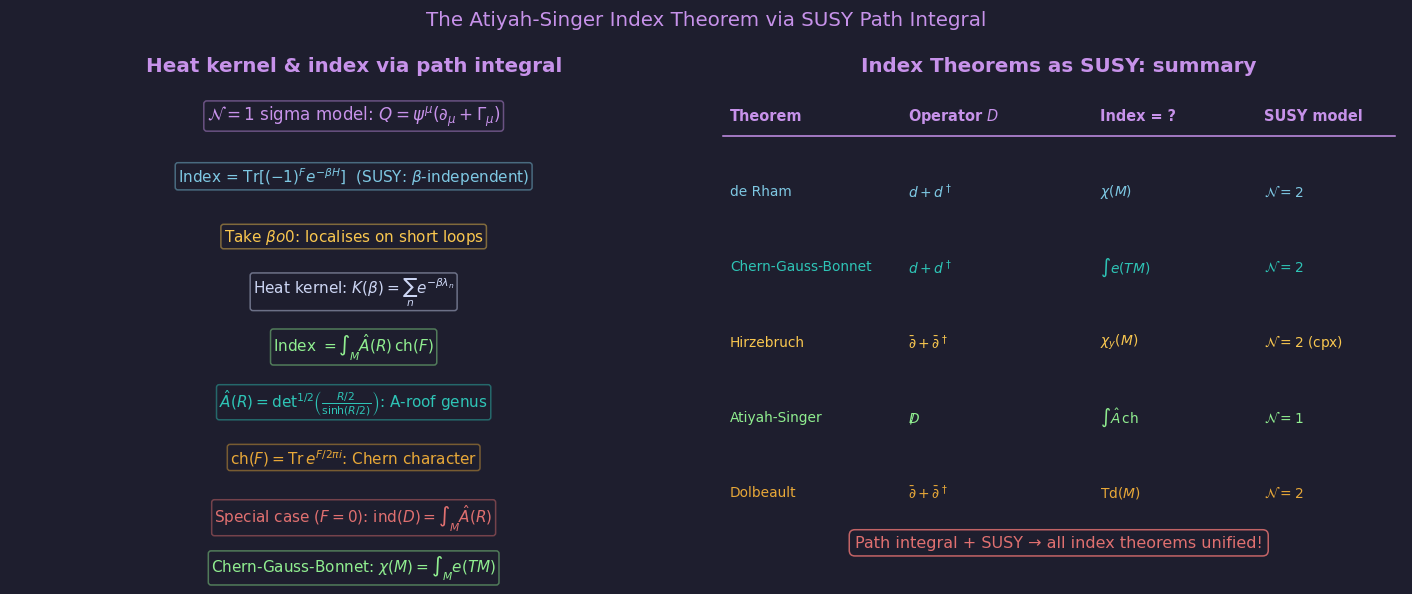

In [6]:
# ── Figure 5: Atiyah-Singer index theorem ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('The Atiyah-Singer Index Theorem via SUSY Path Integral',
             color=PURP, fontsize=13)

# Left: heat kernel expansion and index
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title('Heat kernel & index via path integral', color=PURP)
ax.axis('off')

items = [
    (0.5, 0.93, r'$\mathcal{N}=1$ sigma model: $Q = \psi^\mu(\partial_\mu + \Gamma_\mu)$', PURP),
    (0.5, 0.81, r'Index = $\mathrm{Tr}[(-1)^F e^{-\beta H}]$  (SUSY: $\beta$-independent)', BLUE),
    (0.5, 0.69, r'Take $\beta\to 0$: localises on short loops', YELL),
    (0.5, 0.58,
     r'Heat kernel: $K(\beta) = \sum_n e^{-\beta\lambda_n}$', FG),
    (0.5, 0.47,
     r'Index $= \int_M \hat{A}(R)\,\mathrm{ch}(F)$', GREEN),
    (0.5, 0.36, r'$\hat{A}(R) = \det^{1/2}\!\left(\frac{R/2}{\sinh(R/2)}\right)$: A-roof genus', TEAL),
    (0.5, 0.25, r'$\mathrm{ch}(F) = \mathrm{Tr}\,e^{F/2\pi i}$: Chern character', ORAN),
    (0.5, 0.13,
     r'Special case ($F=0$): $\mathrm{ind}(D) = \int_M \hat{A}(R)$', RED),
    (0.5, 0.03,
     r'Chern-Gauss-Bonnet: $\chi(M) = \int_M e(TM)$', GREEN),
]
for x_, y_, txt, col in items:
    fs = 11 if y_ > 0.85 else 10
    ax.text(x_, y_, txt, ha='center', va='center', fontsize=fs, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18', fc=BG, ec=col, alpha=0.45))

# Right: comparison table of index theorems
ax = axes[1]
ax.set_facecolor(BG)
ax.set_title('Index Theorems as SUSY: summary', color=PURP)
ax.axis('off')

headers2 = ['Theorem', 'Operator $D$', 'Index = ?', 'SUSY model']
rows2 = [
    ['de Rham', r'$d+d^\dagger$', r'$\chi(M)$', r'$\mathcal{N}=2$'],
    ['Chern-Gauss-Bonnet', r'$d+d^\dagger$', r'$\int e(TM)$', r'$\mathcal{N}=2$'],
    ['Hirzebruch', r'$\bar\partial+\bar\partial^\dagger$', r'$\chi_y(M)$', r'$\mathcal{N}=2$ (cpx)'],
    ['Atiyah-Singer', r'$D\!\!\!\!/$', r'$\int \hat{A}\,\mathrm{ch}$', r'$\mathcal{N}=1$'],
    ['Dolbeault', r'$\bar\partial+\bar\partial^\dagger$', r'$\mathrm{Td}(M)$', r'$\mathcal{N}=2$'],
]
col2_xs = [0.02, 0.28, 0.56, 0.80]
row2_ys = np.linspace(0.93, 0.18, len(rows2)+1)

for j, h in enumerate(headers2):
    ax.text(col2_xs[j], row2_ys[0], h, ha='left', va='center', fontsize=9.5,
            color=PURP, fontweight='bold', transform=ax.transAxes)
ax.axhline(row2_ys[0]-0.04, xmin=0.01, xmax=0.99, color=PURP, lw=1) #, transform=ax.transAxes)

row_cols = [BLUE, TEAL, YELL, GREEN, ORAN]
for i, (row, col) in enumerate(zip(rows2, row_cols)):
    y = row2_ys[i+1]
    for j, val in enumerate(row):
        ax.text(col2_xs[j], y, val, ha='left', va='center', fontsize=9,
                color=col, transform=ax.transAxes)

ax.text(0.5, 0.08,
        'Path integral + SUSY → all index theorems unified!',
        ha='center', va='center', fontsize=10.5, color=RED,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.35', fc=BG, ec=RED, alpha=0.85))

plt.tight_layout()
save('fig05_atiyah_singer.png', fig)


In [7]:
import shutil
shutil.make_archive('susyqm_ch03_figures', 'zip', 'figures/ch03')
try:
    from google.colab import files
    files.download('susyqm_ch03_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch03/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
